**Instructions:**

- Do not write your name on the assignment. Be careful about any warnings that might display some file path with your name included.
- Receiving help from classmates and/or ideas from Generative AI is allowed. **However, you must submit your own original work.**
- For questions that require coding, you need to write the relevant code and display its output. Your output should either be the direct answer to the question or clearly display the answer in it.
- For questions that require a written answer (sometimes along with the code), you need to put your answer in a Markdown cell. Writing the answer as a comment or as a print line is not acceptable.
- You need to render this file as HTML using Quarto and submit the HTML file. **Please note that this is a requirement and not optional.** A submission cannot be graded until it is properly rendered.

Import all the libraries and tools you need below.

In [10]:
import tensorflow as tf
import keras
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt

Run the line given below to read the MNIST dataset. Reshape the training and test features. One-hot-encode the training target/response values. (This should be ready from the previous exercise set.)

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.reshape(60000, 784)
x_test = x_test.reshape(10000, 784)

y_train_encoded = keras.utils.to_categorical(y_train)

### 1)

(Standard) scale the training and the test datasets. **(2.5 points)** 

In [4]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

### 2)

Create a neural network classifier with the following specifications:

- 5 hidden layers with 500, 200, 100, 50, and 20 nodes, respectively.
- The non-linear (activation) functions from the previous exercise set.
- A dropout rate of 0.3 for each hidden layer.
- All layers (except the input layer) initialized with `HeNormal`

**Do not use anything that is not instructed in the network.**

**(50 points)**

In [6]:

model = keras.Sequential([
    keras.layers.InputLayer(shape=(784,)),
    keras.layers.Dense(500, activation="relu", kernel_initializer="he_normal"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(200, activation="relu", kernel_initializer="he_normal"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(100, activation="relu", kernel_initializer="he_normal"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(50, activation="relu", kernel_initializer="he_normal"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(20, activation="relu", kernel_initializer="he_normal"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10, activation="softmax", kernel_initializer="he_normal")
])

### 3)

Compile the network with the same cost function as in the previous exercise set and the `adam` optimizer. Print the network summary. **(7.5 points)**

In [7]:
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam"
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 500)            │       392,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 200)            │       100,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 100)            │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 20)             │         1,020 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 519,080 (1.98 MB)

 Trainable params: 519,080 (1.98 MB)

 Non-trainable params: 0 (0.00 B)

### 4)

Create an object that checks the validation loss for a 10-epoch window and stops the training if the validation loss is not decreasing for the entire window.

Train the network for 50 epochs. Use a batch size of 1000, validation split of 10% and the early stopping settings as described above. Save the training line to an output variable, named `history`.

**(30 points)**

In [8]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10
)

history = model.fit(
    x_train_scaled,
    y_train_encoded,
    epochs=50,
    batch_size=1000,
    validation_split=0.1,
    callbacks=[early_stopping]
)

Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 2.0633 - val_loss: 1.0664
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.2171 - val_loss: 0.4232
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.8076 - val_loss: 0.2915
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.6137 - val_loss: 0.2123
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.5085 - val_loss: 0.1830
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.4285 - val_loss: 0.1621
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.3746 - val_loss: 0.1540
Epoch 8/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.3453 - val_loss: 0.1482
Epoch 9/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.3167 - val_loss: 0.1223
Epoch 10/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.2876 - val_loss: 0.1260
Epoch 11/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.2684 - val_loss: 0.1293
Epoch 12/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.2

### 5)

Print the test accuracy and confusion matrix. You should see a test accuracy above 97%. **(2.5 points)**

In [9]:
y_pred = model.predict(x_test_scaled)
y_pred_classes = np.argmax(y_pred, axis=1)

print("Test accuracy:", accuracy_score(y_test, y_pred_classes))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_classes))

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 802us/step
Test accuracy: 0.9793
Confusion matrix:
[[ 969    0    0    1    0    1    4    1    4    0]
 [   0 1124    2    2    0    2    2    1    2    0]
 [   4    2 1006    2    2    0    2    6    7    1]
 [   0    0    2  992    0    7    0    3    5    1]
 [   0    0    3    1  962    0    5    1    0   10]
 [   2    0    0    4    1  873    3    2    6    1]
 [   2    2    1    0    3    6  940    0    4    0]
 [   1    1   10    1    0    0    0 1006    3    6]
 [   1    1    2    5    8    6    0    5  945    1]
 [   3    2    0    8    9    2    0    6    3  976]]


### 6)

Using the `history` variable, visualize the training and validation cost (loss) throughout all epochs. If you put both costs on the same graph, use a legend.

**(7.5 points)**

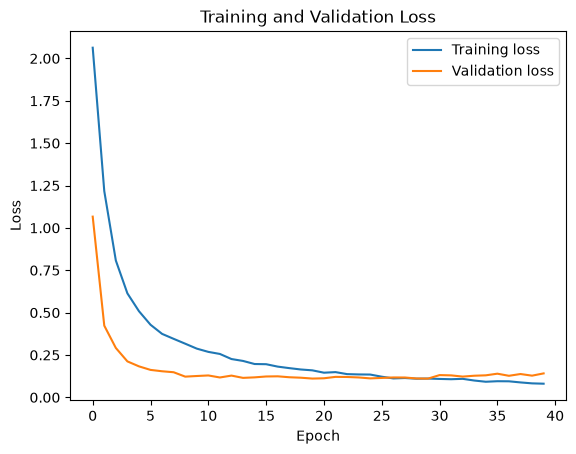

In [11]:
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()